# Histograma manual 

In [1]:
import sys
from pathlib import Path

# O kernel inicia na pasta DESTE caderno — localiza a raiz do projeto:
RAIZ = Path.cwd()
if not (RAIZ / "src" / "leitura.py").exists():
    RAIZ = RAIZ.parent          # kernel começou dentro de notebooks/
sys.path.insert(0, str(RAIZ))   # raiz no path -> 'from src...' funciona

# Imports padrão de todos os cadernos:
from src.leitura import (PASTA_IMAGENS, PASTA_RESULTADOS, carregar_imagem,
                         nome_da_mascara, criar_pastas_resultados, auditar_base)
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("raiz do projeto:", RAIZ)

raiz do projeto: /home/isadora/Documentos/ProcessIMg


ISIC_0010206: manual == cv2.calcHist? True | soma normalizada = 1.000000 | nível mais frequente = 241
ISIC_0012940: manual == cv2.calcHist? True | soma normalizada = 1.000000 | nível mais frequente = 171


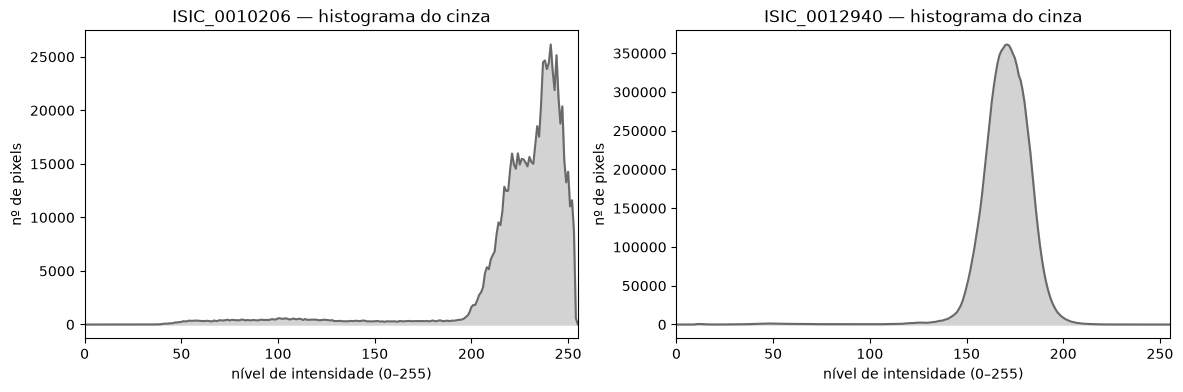

In [2]:
from src.preprocessamento import para_cinza, histograma

alvo = PASTA_RESULTADOS / "histogramas"
imagens = ["ISIC_0010206.jpg", "ISIC_0012940.jpg"]   # fácil, depois difícil

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, nome in zip(axes, imagens):
    cinza = para_cinza(carregar_imagem(PASTA_IMAGENS / nome))
    hist = histograma(cinza)

    # validação: implementação própria vs OpenCV (deve ser True — contagem exata)
    hist_cv = cv2.calcHist([cinza], [0], None, [256], [0, 256]).ravel()
    print(f"{Path(nome).stem}: manual == cv2.calcHist? "
          f"{np.array_equal(hist.astype(np.float64), hist_cv.astype(np.float64))} | "
          f"soma normalizada = {histograma(cinza, normalizar=True).sum():.6f} | "
          f"nível mais frequente = {hist.argmax()}")

    ax.plot(hist, color="dimgray")
    ax.fill_between(range(256), hist, color="lightgray")
    ax.set_title(f"{Path(nome).stem} — histograma do cinza")
    ax.set_xlabel("nível de intensidade (0–255)")
    ax.set_ylabel("nº de pixels")
    ax.set_xlim(0, 255)

fig.savefig(alvo / "histogramas_cinza.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close(fig)